<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/pendulum_jumping_bug_5_regimes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Bug 5 motions.

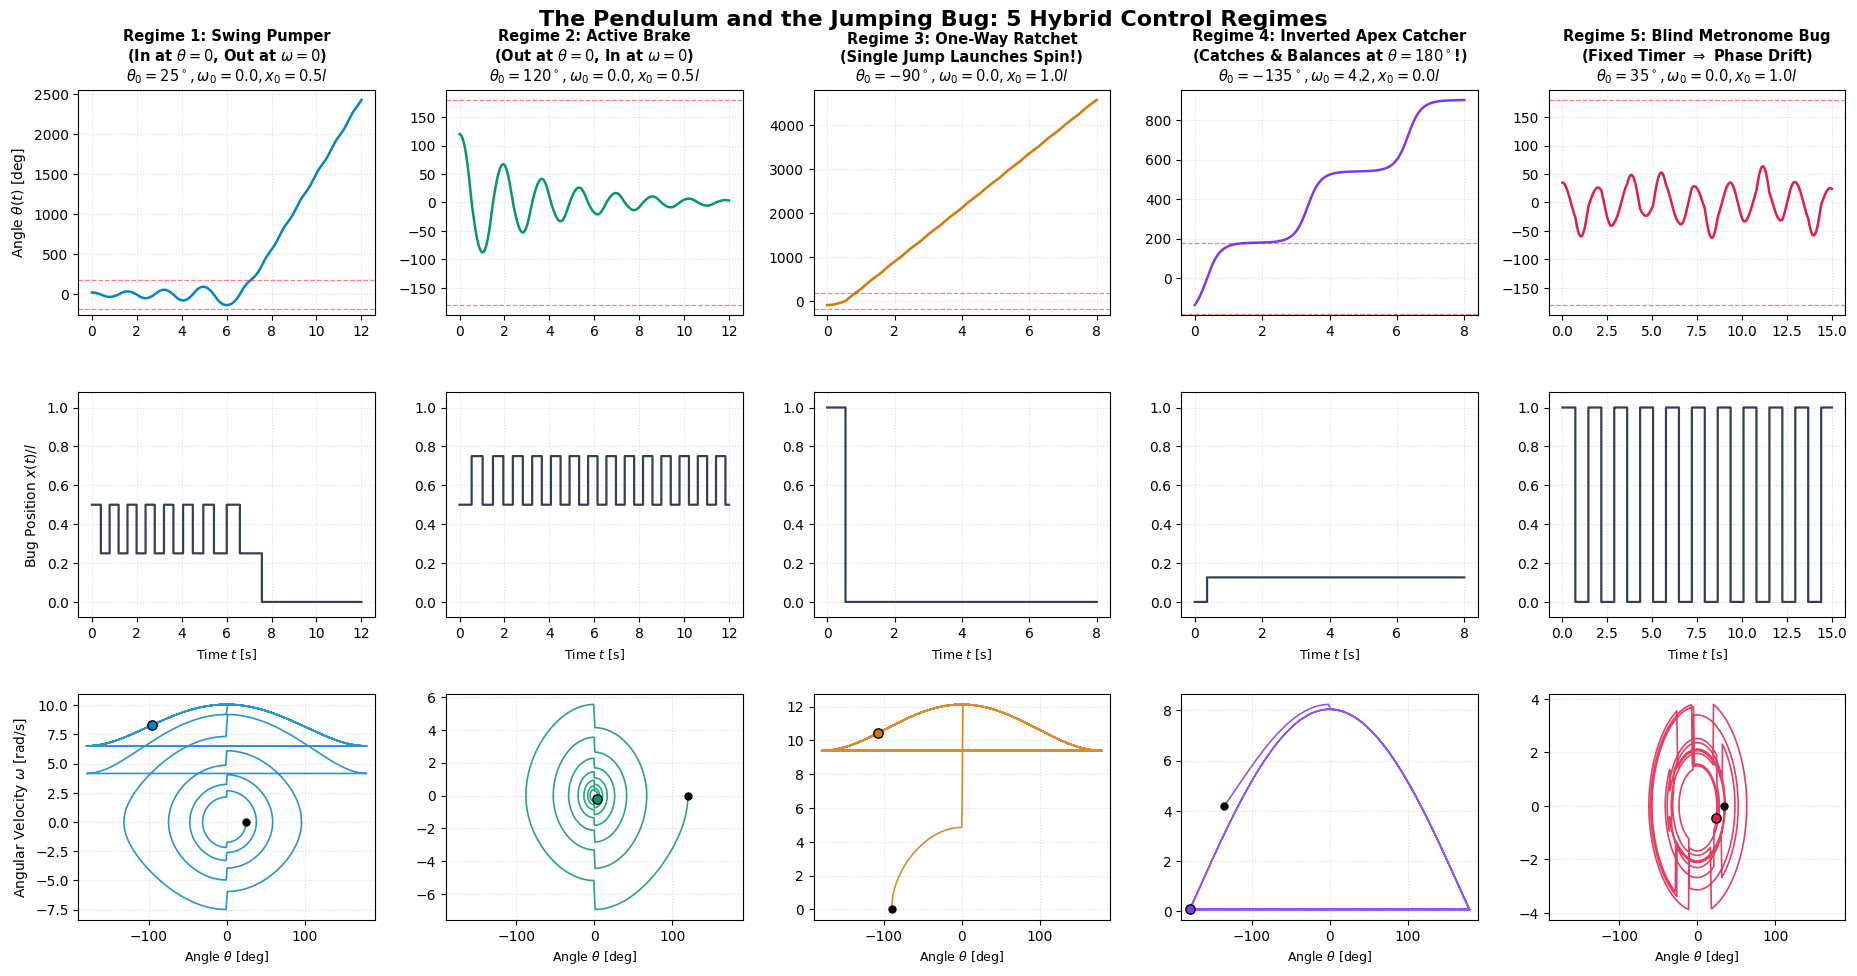

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# =============================================================================
# 1. PHYSICAL PARAMETERS & HELPER FUNCTIONS
# =============================================================================
m = 1.0       # Mass of rod (kg)
m_b = 0.5     # Mass of bug (kg)
l = 1.0       # Length of rod (m)
g = 9.81      # Gravity (m/s^2)
dx = 0.25 * l # Step size for incremental pumping/damping (Regimes 1 & 2)

def I_moment(x):
    """Moment of inertia about pivot when bug is at position x."""
    return (1.0 / 3.0) * m * l**2 + m_b * x**2

def kappa_torque(x):
    """Gravitational torque coefficient when bug is at position x."""
    return g * (0.5 * m * l + m_b * x)

def total_energy(theta, omega, x):
    """Total mechanical energy E = K + V."""
    K = 0.5 * I_moment(x) * omega**2
    V = -kappa_torque(x) * np.cos(theta)
    return K + V

def solve_apex_catcher_position(omega_minus, x_old):
    """
    Finds the exact landing spot x_catch in [0, l] at theta = 0 so that
    the post-jump energy E+ equals the upside-down apex barrier +kappa(x_catch).
    """
    K_minus = 0.5 * I_moment(x_old) * omega_minus**2
    I_old = I_moment(x_old)

    def residual(x_new):
        K_plus = K_minus * (I_old / I_moment(x_new))
        # At theta = 0, E+ = K+ - kappa(x_new). We want E+ = +kappa(x_new) => K+ = 2*kappa(x_new)
        return K_plus - 2.0 * kappa_torque(x_new)

    if residual(0.0) <= 0.0:
        return 0.0
    if residual(l) >= 0.0:
        return l
    return brentq(residual, 0.0, l)

def rod_ode(t, state, x_n):
    """Continuous flow between jumps: state = [theta, omega]."""
    theta, omega = state
    alpha = -(kappa_torque(x_n) / I_moment(x_n)) * np.sin(theta)
    return [omega, alpha]

# =============================================================================
# 2. HYBRID EVENT-DRIVEN SIMULATOR FOR ALL 5 REGIMES
# =============================================================================
def simulate_jumping_bug(regime, theta0, omega0, x0, t_max=12.0, dt=0.005):
    t_cur = 0.0
    th_cur, om_cur, x_cur = theta0, omega0, x0

    t_hist = [t_cur]
    th_hist = [th_cur]
    om_hist = [om_cur]
    x_hist = [x_cur]
    E_hist = [total_energy(th_cur, om_cur, x_cur)]

    caught_apex = False
    T_clock = 0.72  # Metronome half-period for Regime 5 (seconds)
    next_clock_jump = T_clock

    while t_cur < t_max:
        t_next = min(t_cur + dt, t_max)
        sol = solve_ivp(rod_ode, [t_cur, t_next], [th_cur, om_cur], args=(x_cur,), rtol=1e-9, atol=1e-9)
        th_new, om_new = sol.y[0, -1], sol.y[1, -1]

        # Detect zero crossings
        crossed_bottom = (np.sin(th_cur) * np.sin(th_new) <= 0.0) and (np.cos(th_new) > 0.0) and (t_cur > 0.02)
        crossed_apex   = (om_cur * om_new <= 0.0) and (t_cur > 0.02)

        x_new = x_cur

        # ---------------------------------------------------------------------
        # CONTROL LAWS FOR THE 5 REGIMES
        # ---------------------------------------------------------------------
        if regime == 1:  # Case 1: Swing Pumper
            if crossed_apex:
                x_new = min(l, x_cur + dx)
            elif crossed_bottom:
                x_new = max(0.0, x_cur - dx)

        elif regime == 2:  # Case 2: Active Brake
            if crossed_apex:
                x_new = max(0.0, x_cur - dx)
            elif crossed_bottom:
                x_new = min(l, x_cur + dx)

        elif regime == 3:  # Case 3: Asymmetric Ratchet (Pumps only on +omega swing)
            if crossed_bottom and om_new > 0.0:
                x_new = 0.0  # Full jump to pivot at bottom going right
            elif crossed_apex and np.sin(th_new) > 0.0:
                x_new = l    # Jump back to tip at right apex

        elif regime == 4:  # Case 4: Inverted Apex Catcher
            if (not caught_apex) and crossed_bottom and om_new > 0.0:
                x_new = solve_apex_catcher_position(om_new, x_cur)
                caught_apex = True

        elif regime == 5:  # Case 5: Blind Metronome Bug (Time-Triggered)
            if t_next >= next_clock_jump:
                x_new = 0.0 if x_cur > 0.5 * l else l
                next_clock_jump += T_clock

        # Apply Discrete Angular Momentum Map if bug jumped
        if abs(x_new - x_cur) > 1e-9:
            om_new = om_new * (I_moment(x_cur) / I_moment(x_new))
            x_cur = x_new

        t_cur = t_next
        th_cur, om_cur = th_new, om_new

        t_hist.append(t_cur)
        th_hist.append(th_cur)
        om_hist.append(om_cur)
        x_hist.append(x_cur)
        E_hist.append(total_energy(th_cur, om_cur, x_cur))

    return np.array(t_hist), np.array(th_hist), np.array(om_hist), np.array(x_hist), np.array(E_hist)

# =============================================================================
# 3. RUN ALL 5 REGIMES AND PLOT DASHBOARD
# =============================================================================
configs = [
    (1, "Regime 1: Swing Pumper\n(In at $\\theta=0$, Out at $\\omega=0$)", np.radians(25.0), 0.0, 0.5*l, 12.0, "#0284c7"),
    (2, "Regime 2: Active Brake\n(Out at $\\theta=0$, In at $\\omega=0$)", np.radians(120.0), 0.0, 0.5*l, 12.0, "#059669"),
    (3, "Regime 3: One-Way Ratchet\n(Single Jump Launches Spin!)", np.radians(-90.0), 0.0, l, 8.0, "#d97706"),
    (4, "Regime 4: Inverted Apex Catcher\n(Catches & Balances at $\\theta=180^\\circ$!)", np.radians(-135.0), 0.0, 0.0, 8.0, "#7c3aed"),
    (5, "Regime 5: Blind Metronome Bug\n(Fixed Timer $\\Rightarrow$ Phase Drift)", np.radians(35.0), 0.0, l, 15.0, "#e11d48"),
]

fig, axs = plt.subplots(3, 5, figsize=(19, 10))
fig.suptitle("The Pendulum and the Jumping Bug: 5 Hybrid Control Regimes", fontsize=16, fontweight="bold", y=0.98)

for col, (reg_id, title, th0, om0, x0, tmax, color) in enumerate(configs):
    # For Regime 4, give it an initial speed at -135 deg so it would normally overshoot the top
    if reg_id == 4:
        om0 = 4.2
    # Append parameters to the title
    th0_deg = np.degrees(th0)
    params_str = f"$\\theta_0={th0_deg:.0f}^\\circ, \\omega_0={om0:.1f}, x_0={x0/l:.1f}l$"
    full_title = f"{title}\n{params_str}"
    t, th, om, x, E = simulate_jumping_bug(reg_id, th0, om0, x0, t_max=tmax)

    # Row 0: Angle theta(t) in degrees
    ax_th = axs[0, col]
    ax_th.plot(t, np.degrees(th), color=color, lw=1.8)
    ax_th.axhline(180, color="r", ls="--", lw=0.9, alpha=0.5, label="$\\pm 180^\\circ$ Apex")
    ax_th.axhline(-180, color="r", ls="--", lw=0.9, alpha=0.5)
    ax_th.set_title(full_title, fontsize=10.5, fontweight="bold")
    if col == 0:
        ax_th.set_ylabel("Angle $\\theta(t)$ [deg]", fontsize=10)
    ax_th.grid(True, ls=":", alpha=0.4)

    # Row 1: Bug Position x(t)
    ax_x = axs[1, col]
    ax_x.step(t, x, where="post", color="#334155", lw=1.6)
    ax_x.set_ylim(-0.08 * l, 1.08 * l)
    if col == 0:
        ax_x.set_ylabel("Bug Position $x(t) / l$", fontsize=10)
    ax_x.set_xlabel("Time $t$ [s]", fontsize=9)
    ax_x.grid(True, ls=":", alpha=0.4)

    # Row 2: Phase Portrait (theta wrapped to [-180, 180] vs omega)
    ax_ph = axs[2, col]
    th_wrapped = np.degrees(((th + np.pi) % (2.0 * np.pi)) - np.pi)
    ax_ph.plot(th_wrapped, om, color=color, lw=1.2, alpha=0.85)
    ax_ph.scatter([th_wrapped[0]], [om[0]], color="k", s=25, zorder=5, label="Start")
    ax_ph.scatter([th_wrapped[-1]], [om[-1]], color=color, edgecolor="k", s=45, zorder=6, label="End")
    ax_ph.set_xlim(-190, 190)
    if col == 0:
        ax_ph.set_ylabel("Angular Velocity $\\omega$ [rad/s]", fontsize=10)
    ax_ph.set_xlabel("Angle $\\theta$ [deg]", fontsize=9)
    ax_ph.grid(True, ls=":", alpha=0.4)

plt.subplots_adjust(left=0.05, right=0.98, bottom=0.07, top=0.90, wspace=0.24, hspace=0.34)
plt.show()